In [13]:
!pip install -q -U "transformers>=4.56" accelerate torchinfo
import torch
print(torch.__version__, "| CUDA:", torch.cuda.is_available())
!nvidia-smi --query-gpu=name,memory.total --format=csv

2.14.1+cu130 | CUDA: False
/bin/bash: line 1: nvidia-smi: command not found


# Hugging Face Authentication


In [29]:
from google.colab import userdata
from huggingface_hub import login
login(token=userdata.get("HF_TOKEN"))

#Load the model: DINOv2 teardown

In [21]:
import torch, requests
import matplotlib.pyplot as plt
from PIL import Image
from collections import OrderedDict
from transformers import AutoModel, AutoImageProcessor
from torchinfo import summary

# Options DINOv2:
#   facebook/dinov2-small | dinov2-base | dinov2-large | dinov2-giant
#   facebook/dinov2-with-registers-small | -base | -large | -giant
MODEL_ID = "facebook/dinov2-with-registers-base"
device = "cuda" if torch.cuda.is_available() else "cpu"

processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModel.from_pretrained(MODEL_ID).to(device).eval()

# ---- Config ----
cfg = model.config
print("=== CONFIG ===")
for k in ["hidden_size", "num_hidden_layers", "num_attention_heads",
          "mlp_ratio", "patch_size", "image_size", "layerscale_value",
          "use_swiglu_ffn", "num_register_tokens"]:
    print(f"{k:22s}: {getattr(cfg, k, 'n/a')}")

# ---- Parameters ----
count = lambda m: sum(p.numel() for p in m.parameters())
total = count(model)
print(f"\n=== PARAMETERS === total: {total/1e6:.2f}M")
for name, child in model.named_children():
    n = count(child)
    print(f"{name:15s} {n/1e6:8.3f}M  ({100*n/total:5.1f}%)")

print("\n=== ONE TRANSFORMER BLOCK (encoder.layer[0]) ===")
for name, child in model.encoder.layer[0].named_children():
    print(f"{name:15s} {count(child)/1e6:8.3f}M  {child.__class__.__name__}")

print("\n=== ARCHITECTURE ===")
print(model.embeddings)
print(model.encoder.layer[0])

Loading weights:   0%|          | 0/224 [00:00<?, ?it/s]

=== CONFIG ===
hidden_size           : 768
num_hidden_layers     : 12
num_attention_heads   : 12
mlp_ratio             : 4
patch_size            : 14
image_size            : 518
layerscale_value      : 1.0
use_swiglu_ffn        : False
num_register_tokens   : 4

=== PARAMETERS === total: 86.58M
embeddings         1.509M  (  1.7%)
encoder           85.073M  ( 98.3%)
layernorm          0.002M  (  0.0%)

=== ONE TRANSFORMER BLOCK (encoder.layer[0]) ===
norm1              0.002M  LayerNorm
attention          2.362M  Dinov2WithRegistersAttention
layer_scale1       0.001M  Dinov2WithRegistersLayerScale
drop_path          0.000M  Identity
norm2              0.002M  LayerNorm
mlp                4.722M  Dinov2WithRegistersMLP
layer_scale2       0.001M  Dinov2WithRegistersLayerScale

=== ARCHITECTURE ===
Dinov2WithRegistersEmbeddings(
  (patch_embeddings): Dinov2WithRegistersPatchEmbeddings(
    (projection): Conv2d(3, 768, kernel_size=(14, 14), stride=(14, 14))
  )
  (dropout): Dropout(p=0.0, i


Input pixel_values: (1, 3, 224, 224)

=== SHAPES THROUGH THE NETWORK ===
embeddings       (1, 261, 768)
layer[0]         (1, 261, 768)
layer[6]         (1, 261, 768)
layer[11]        (1, 261, 768)
final_layernorm  (1, 261, 768)

=== TOKENS ===
last_hidden_state: (1, 261, 768)
CLS              : (1, 768)
Registers        : 4
Patches (16x16)  : (1, 256, 768) -> (1, 16, 16, 768)
pooler_output    : (1, 768)
num hidden_states: 13


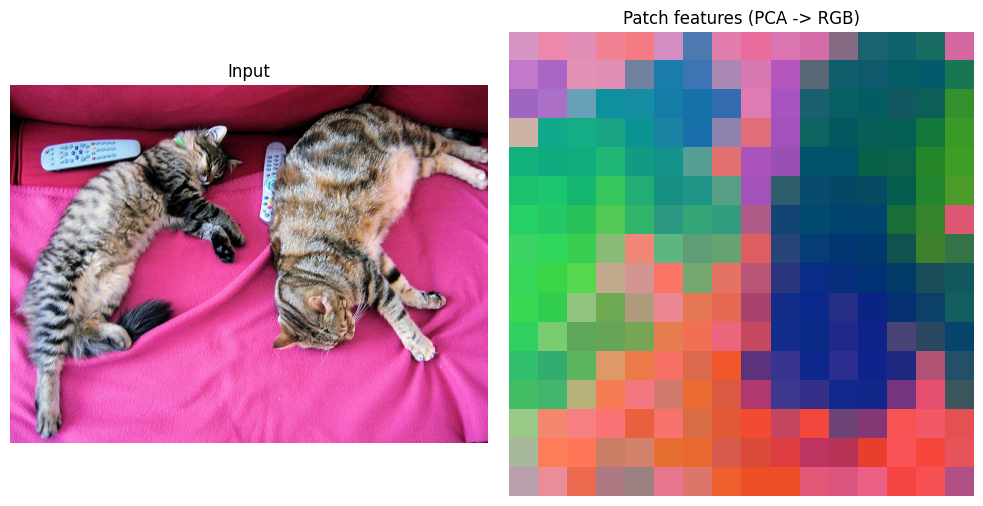

In [27]:
# ---- Forward pass + shape hooks ----
url = "http://images.cocodataset.org/val2017/000000039769.jpg"
image = Image.open(requests.get(url, stream=True).raw).convert("RGB")
inputs = processor(images=image, return_tensors="pt").to(device)
print("\nInput pixel_values:", tuple(inputs["pixel_values"].shape))

shapes = OrderedDict()
def make_hook(name):
    def hook(_, __, out):
        out = out[0] if isinstance(out, tuple) else out
        if torch.is_tensor(out):
            shapes[name] = tuple(out.shape)
    return hook

L = len(model.encoder.layer)
handles = [model.embeddings.register_forward_hook(make_hook("embeddings"))]
for i in (0, L // 2, L - 1):
    handles.append(model.encoder.layer[i].register_forward_hook(make_hook(f"layer[{i}]")))
handles.append(model.layernorm.register_forward_hook(make_hook("final_layernorm")))

with torch.inference_mode():
    out = model(**inputs, output_hidden_states=True)
for h in handles:
    h.remove()

print("\n=== SHAPES THROUGH THE NETWORK ===")
for k, v in shapes.items():
    print(f"{k:16s} {v}")

# ---- Token layout: [CLS] + [registers (if any)] + [patches] ----
hs = out.last_hidden_state
R = getattr(cfg, "num_register_tokens", 0)
P = cfg.patch_size
H = inputs["pixel_values"].shape[-2] // P
W = inputs["pixel_values"].shape[-1] // P

cls_tok = hs[:, 0]
patch_toks = hs[:, 1 + R:]
patch_map = patch_toks.reshape(1, H, W, -1)

print("\n=== TOKENS ===")
print("last_hidden_state:", tuple(hs.shape))
print("CLS              :", tuple(cls_tok.shape))
print(f"Registers        : {R}")
print(f"Patches ({H}x{W})  :", tuple(patch_toks.shape), "->", tuple(patch_map.shape))
print("pooler_output    :", tuple(out.pooler_output.shape))
print("num hidden_states:", len(out.hidden_states))

# ---- PCA visualization of patch features ----
feats = patch_toks[0].float().cpu()
feats = feats - feats.mean(0)
U, S, V = torch.pca_lowrank(feats, q=3)
pca = (feats @ V[:, :3]).reshape(H, W, 3)
pca = (pca - pca.min()) / (pca.max() - pca.min())

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(image); ax[0].set_title("Input"); ax[0].axis("off")
ax[1].imshow(pca.numpy()); ax[1].set_title("Patch features (PCA -> RGB)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

In [28]:
summary(model, input_data={"pixel_values": inputs["pixel_values"]}, depth=3)

Layer (type:depth-idx)                                       Output Shape              Param #
Dinov2WithRegistersModel                                     [1, 768]                  --
├─Dinov2WithRegistersEmbeddings: 1-1                         [1, 261, 768]             1,056,768
│    └─Dinov2WithRegistersPatchEmbeddings: 2-1               [1, 256, 768]             --
│    │    └─Conv2d: 3-1                                      [1, 768, 16, 16]          452,352
│    └─Dropout: 2-2                                          [1, 261, 768]             --
├─Dinov2WithRegistersEncoder: 1-2                            [1, 261, 768]             --
│    └─ModuleList: 2-3                                       --                        --
│    │    └─Dinov2WithRegistersLayer: 3-2                    [1, 261, 768]             7,089,408
│    │    └─Dinov2WithRegistersLayer: 3-3                    [1, 261, 768]             7,089,408
│    │    └─Dinov2WithRegistersLayer: 3-4                    [1, 261,

#DINO V3

In [30]:
from transformers import AutoModel, AutoImageProcessor

# ---------------------------------------------------------------
# 1. Download model
# Other options: dinov3-vits16 / vitb16 / vitl16 / vith16plus / vit7b16
#   facebook/dinov3-convnext-tiny-pretrain-lvd1689m (ConvNeXt versions)
#   facebook/dinov3-vitl16-pretrain-sat493m         (satellite domain)
# ---------------------------------------------------------------
MODEL_ID = "facebook/dinov3-vits16-pretrain-lvd1689m"
device = "cuda" if torch.cuda.is_available() else "cpu"

processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModel.from_pretrained(MODEL_ID).to(device).eval()
print("Loaded:", MODEL_ID, "on", device)

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Loaded: facebook/dinov3-vits16-pretrain-lvd1689m on cpu


=== CONFIG ===
hidden_size           : 384
num_hidden_layers     : 12
num_attention_heads   : 6
intermediate_size     : 1536
patch_size            : 16
num_register_tokens   : 4
image_size            : 224
layerscale_value      : 1.0
use_gated_mlp         : False

=== PARAMETERS === total: 21.60M
embeddings              0.298M  (  1.4%)
rope_embeddings         0.000M  (  0.0%)
model                  21.298M  ( 98.6%)
norm                    0.001M  (  0.0%)

=== ARCHITECTURE ===
DINOv3ViTEmbeddings(
  (patch_embeddings): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
)

Input pixel_values: (1, 3, 224, 224)

=== SHAPES THROUGH THE NETWORK ===
embeddings   (1, 201, 384)
final_norm   (1, 201, 384)

=== TOKENS ===
last_hidden_state: (1, 201, 384)
CLS              : (1, 384)
Registers (4)    : (1, 4, 384)
Patches (14x14)  : (1, 196, 384) -> (1, 14, 14, 384)
pooler_output    : (1, 384)
num hidden_states: 13 (embeddings + each layer)


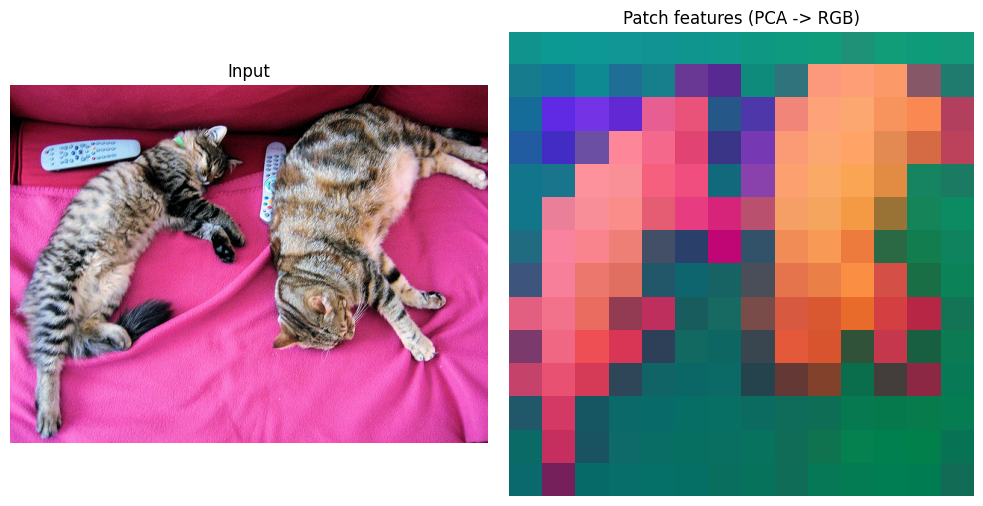

In [33]:
import torch
import requests
from PIL import Image
from collections import OrderedDict
from transformers import AutoModel, AutoImageProcessor

# ---------------------------------------------------------------
# 2. Config teardown
# ---------------------------------------------------------------
cfg = model.config
print("=== CONFIG ===")
for k in ["hidden_size", "num_hidden_layers", "num_attention_heads",
          "intermediate_size", "patch_size", "num_register_tokens",
          "image_size", "layerscale_value", "use_gated_mlp"]:
    print(f"{k:22s}: {getattr(cfg, k, 'n/a')}")

# ---------------------------------------------------------------
# 3. Parameter counts
# ---------------------------------------------------------------
def count(m):
    return sum(p.numel() for p in m.parameters())

total = count(model)
print(f"\n=== PARAMETERS === total: {total/1e6:.2f}M")
for name, child in model.named_children():
    n = count(child)
    print(f"{name:20s} {n/1e6:8.3f}M  ({100*n/total:5.1f}%)")

# Inside a single transformer block
if hasattr(model, "layer"):
    print("\n=== ONE TRANSFORMER BLOCK (layer[0]) ===")
    for name, child in model.layer[0].named_children():
        print(f"{name:15s} {count(child)/1e6:8.3f}M  {child.__class__.__name__}")

# ---------------------------------------------------------------
# 4. Full architecture print (first block only, to keep it short)
# ---------------------------------------------------------------
print("\n=== ARCHITECTURE ===")
print(model.embeddings)
if hasattr(model, "layer"):
    print(model.layer[0])

# ---------------------------------------------------------------
# 5. Forward pass on a sample image + shape tracing with hooks
# ---------------------------------------------------------------
url = "http://images.cocodataset.org/val2017/000000039769.jpg"
image = Image.open(requests.get(url, stream=True).raw).convert("RGB")
inputs = processor(images=image, return_tensors="pt").to(device)
print("\nInput pixel_values:", tuple(inputs["pixel_values"].shape))

shapes = OrderedDict()
def make_hook(name):
    def hook(_, __, out):
        out = out[0] if isinstance(out, tuple) else out
        if torch.is_tensor(out):
            shapes[name] = tuple(out.shape)
    return hook

handles = [model.embeddings.register_forward_hook(make_hook("embeddings"))]
if hasattr(model, "layer"):
    for i in (0, len(model.layer) // 2, len(model.layer) - 1):
        handles.append(model.layer[i].register_forward_hook(make_hook(f"layer[{i}]")))
handles.append(model.norm.register_forward_hook(make_hook("final_norm")))

with torch.inference_mode():
    out = model(**inputs, output_hidden_states=True)

for h in handles:
    h.remove()

print("\n=== SHAPES THROUGH THE NETWORK ===")
for k, v in shapes.items():
    print(f"{k:12s} {v}")

# ---------------------------------------------------------------
# 6. Token layout: [CLS] + [register tokens] + [patch tokens]
# ---------------------------------------------------------------
hs = out.last_hidden_state                      # (B, 1 + R + N, D)
R = cfg.num_register_tokens
P = cfg.patch_size
cls_tok = hs[:, 0]                              # global descriptor
reg_toks = hs[:, 1:1 + R]                       # register tokens
patch_toks = hs[:, 1 + R:]                      # dense features

H = inputs["pixel_values"].shape[-2] // P
W = inputs["pixel_values"].shape[-1] // P
patch_map = patch_toks.reshape(1, H, W, -1)     # spatial feature map

print("\n=== TOKENS ===")
print("last_hidden_state:", tuple(hs.shape))
print("CLS              :", tuple(cls_tok.shape))
print(f"Registers ({R})    :", tuple(reg_toks.shape))
print(f"Patches ({H}x{W})  :", tuple(patch_toks.shape), "->", tuple(patch_map.shape))
print("pooler_output    :", tuple(out.pooler_output.shape))
print("num hidden_states:", len(out.hidden_states), "(embeddings + each layer)")

# ---------------------------------------------------------------
# 7. Quick PCA visualization of patch features (the classic DINO demo)
# ---------------------------------------------------------------
import matplotlib.pyplot as plt

feats = patch_toks[0].float().cpu()
feats = feats - feats.mean(0)
U, S, V = torch.pca_lowrank(feats, q=3)
pca = (feats @ V[:, :3]).reshape(H, W, 3)
pca = (pca - pca.min()) / (pca.max() - pca.min())

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(image); ax[0].set_title("Input"); ax[0].axis("off")
ax[1].imshow(pca.numpy()); ax[1].set_title("Patch features (PCA -> RGB)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

Comparing DINOv2 vs DINOv3: Dense-feature function

In [36]:
import torch, requests, numpy as np, matplotlib.pyplot as plt, torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
import torchvision.transforms as T
from transformers import AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

IDS = {
    "DINOv2-B (reg)": "facebook/dinov2-with-registers-base",
    "DINOv3-B":       "facebook/dinov3-vitb16-pretrain-lvd1689m",
}
models = {k: AutoModel.from_pretrained(v, torch_dtype=torch.float16).to(device).eval()
          for k, v in IDS.items()}

norm = T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
def prep(img, size):
    x = T.ToTensor()(img.resize((size, size), Image.BICUBIC))
    return norm(x).unsqueeze(0).to(device).half()

@torch.inference_mode()
def dense(model, img, size=448):
    out = model(pixel_values=prep(img, size)).last_hidden_state[0]
    R = getattr(model.config, "num_register_tokens", 0)
    g = size // model.config.patch_size
    return out[1 + R:].float().reshape(g, g, -1)           # (g, g, D) patch map

def load_img(url):
    return Image.open(requests.get(url, stream=True).raw).convert("RGB")

img = load_img("http://images.cocodataset.org/val2017/000000039769.jpg")

def pca_rgb(f):
    h, w, d = f.shape
    x = f.reshape(-1, d); x = x - x.mean(0)
    _, _, V = torch.pca_lowrank(x, q=3)
    p = (x @ V[:, :3]).reshape(h, w, 3)
    return ((p - p.min()) / (p.max() - p.min())).cpu().numpy()

Loading weights:   0%|          | 0/224 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/744 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Resolution scaling (PCA at 224 / 448 / 896)

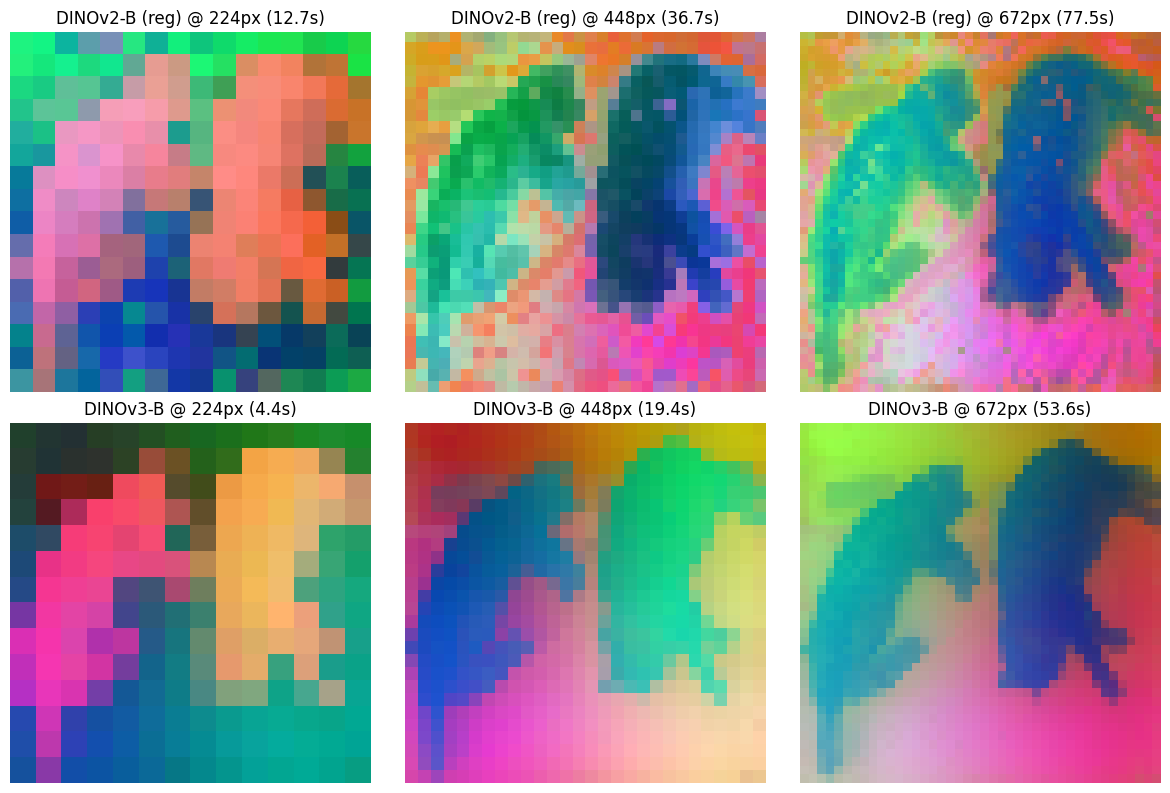

In [38]:
import time
sizes = [224, 448, 672]   # 672 is a multiple of 112, so it works for both patch sizes
fig, ax = plt.subplots(len(models), len(sizes), figsize=(4 * len(sizes), 4 * len(models)))
for r, (name, m) in enumerate(models.items()):
    for c, s in enumerate(sizes):
        t = time.time()
        ax[r, c].imshow(pca_rgb(dense(m, img, s)))
        ax[r, c].set_title(f"{name} @ {s}px ({time.time()-t:.1f}s)"); ax[r, c].axis("off")
plt.tight_layout(); plt.show()

Patch similarity map (dense correspondence)

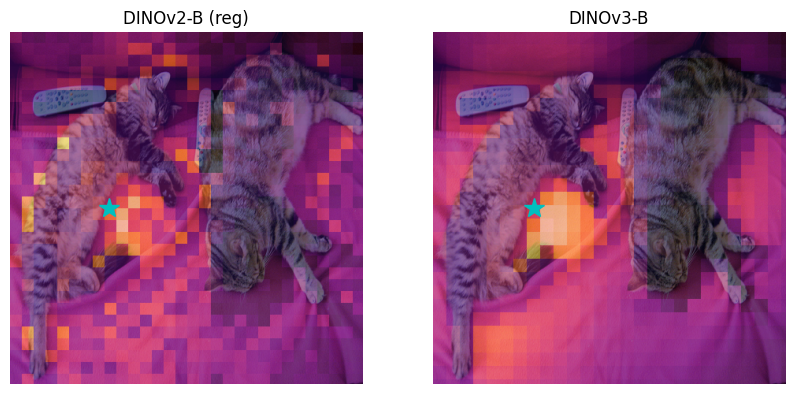

In [39]:
def sim_map(m, img, point=(0.5, 0.3), size=448):
    f = F.normalize(dense(m, img, size), dim=-1)            # (g, g, D)
    g = f.shape[0]
    r, c = int(point[0] * g), int(point[1] * g)
    sim = (f @ f[r, c]).cpu().numpy()                       # (g, g)
    return sim, (r / g, c / g)

fig, ax = plt.subplots(1, len(models), figsize=(5 * len(models), 5))
for a, (name, m) in zip(ax, models.items()):
    s, (ry, cx) = sim_map(m, img, point=(0.5, 0.3))         # (row, col) as fractions
    a.imshow(img.resize((448, 448))); a.imshow(
        np.kron(s, np.ones((448 // s.shape[0] + 1,) * 2))[:448, :448], alpha=0.6, cmap="inferno")
    a.plot(cx * 448, ry * 448, "c*", ms=15); a.set_title(name); a.axis("off")
plt.show()

Feature-norm map

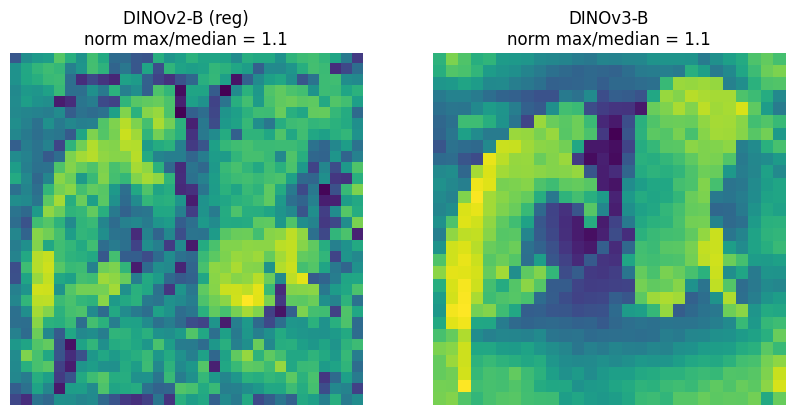

In [40]:
fig, ax = plt.subplots(1, len(models), figsize=(5 * len(models), 5))
for a, (name, m) in zip(ax, models.items()):
    n = dense(m, img, 448).norm(dim=-1).cpu().numpy()
    a.imshow(n, cmap="viridis"); a.set_title(f"{name}\nnorm max/median = {n.max()/np.median(n):.1f}")
    a.axis("off")
plt.show()

Linear segmentation Pascal VOC

In [42]:
import torchvision
VOC = dict(root="/content/data", year="2012", download=True)
voc_tr = torchvision.datasets.VOCSegmentation(image_set="train", **VOC)
voc_va = torchvision.datasets.VOCSegmentation(image_set="val", **VOC)
SIZE, NTR, NVA, C = 448, 400, 300, 21

def extract_seg(model, ds, n):
    X, Y = [], []
    for i in tqdm(range(n)):
        im, m = ds[i]
        X.append(dense(model, im.convert("RGB"), SIZE).half().cpu())
        Y.append(torch.from_numpy(np.array(m.resize((SIZE, SIZE), Image.NEAREST))).long())
    return torch.stack(X), torch.stack(Y)

def seg_probe(Xtr, Ytr, Xva, Yva, epochs=10, bs=4096, lr=1e-3):
    g, D = Xtr.shape[1], Xtr.shape[-1]
    Yg = F.interpolate(Ytr[:, None].float(), size=(g, g), mode="nearest")[:, 0].long()
    Xf, yf = Xtr.reshape(-1, D), Yg.reshape(-1)
    keep = yf != 255
    Xf, yf = Xf[keep].to(device), yf[keep].to(device)
    mu, sd = Xf.float().mean(0), Xf.float().std(0) + 1e-6
    head = torch.nn.Linear(D, C).to(device)
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=1e-4)
    for _ in range(epochs):
        perm = torch.randperm(len(Xf), device=device)
        for i in range(0, len(Xf), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(head((Xf[idx].float() - mu) / sd), yf[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    # evaluation at full mask resolution
    conf = torch.zeros(C, C, device=device)
    with torch.no_grad():
        for x, y in zip(Xva, Yva):
            lg = head((x.to(device).float() - mu) / sd).permute(2, 0, 1)[None]
            pred = F.interpolate(lg, size=(SIZE, SIZE), mode="bilinear")[0].argmax(0)
            y = y.to(device); ok = y != 255
            conf += torch.bincount(y[ok] * C + pred[ok], minlength=C * C).reshape(C, C)
    iou = conf.diag() / (conf.sum(0) + conf.sum(1) - conf.diag()).clamp(min=1)
    return 100 * iou.mean().item()

for name, m in models.items():
    Xtr, Ytr = extract_seg(m, voc_tr, NTR)
    Xva, Yva = extract_seg(m, voc_va, NVA)
    print(f"{name}: VOC linear-seg mIoU = {seg_probe(Xtr, Ytr, Xva, Yva):.2f}%")

KeyboardInterrupt: 

# DINO v3 Teardown

##1. Layer by layer evolution (what each block does)

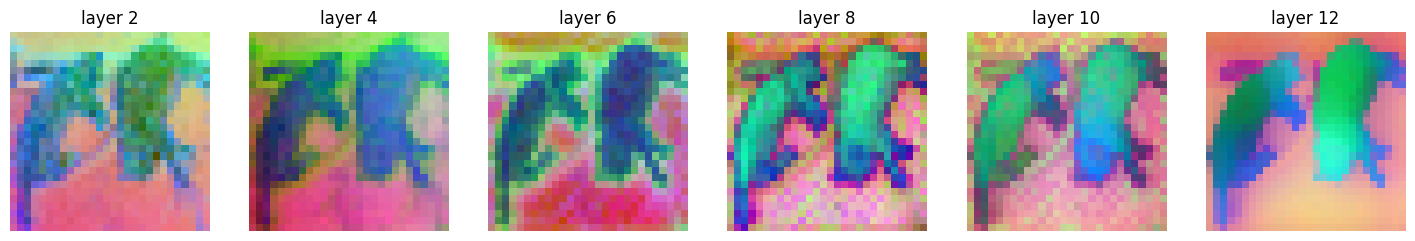

block  1: cos(in,out)=0.610  mean norm=22.5
block  2: cos(in,out)=0.717  mean norm=17.5
block  3: cos(in,out)=0.783  mean norm=28.9
block  4: cos(in,out)=0.828  mean norm=32.4
block  5: cos(in,out)=0.816  mean norm=39.1
block  6: cos(in,out)=0.797  mean norm=49.7
block  7: cos(in,out)=0.773  mean norm=66.9
block  8: cos(in,out)=0.725  mean norm=101.4
block  9: cos(in,out)=0.780  mean norm=157.7
block 10: cos(in,out)=0.789  mean norm=251.5
block 11: cos(in,out)=0.743  mean norm=483.3
block 12: cos(in,out)=0.498  mean norm=1562.9


In [43]:
m = models["DINOv3-B"]
with torch.inference_mode():
    hs = m(pixel_values=prep(img, 448), output_hidden_states=True).hidden_states
R, g = m.config.num_register_tokens, 448 // m.config.patch_size

# PCA of patch features at different depths
layers = [2, 4, 6, 8, 10, 12]
fig, ax = plt.subplots(1, len(layers), figsize=(3 * len(layers), 3.2))
for a, l in zip(ax, layers):
    f = hs[l][0, 1 + R:].float().reshape(g, g, -1)
    a.imshow(pca_rgb(f)); a.set_title(f"layer {l}"); a.axis("off")
plt.show()

# How much each block changes the tokens + how large the features get
for l in range(1, len(hs)):
    a, b = hs[l - 1][0].float(), hs[l][0].float()
    cos = F.cosine_similarity(a, b, dim=-1).mean().item()
    print(f"block {l:2d}: cos(in,out)={cos:.3f}  mean norm={b.norm(dim=-1).mean():.1f}")

##2. CLS attention maps (what the model looks at)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

attention NaN: False


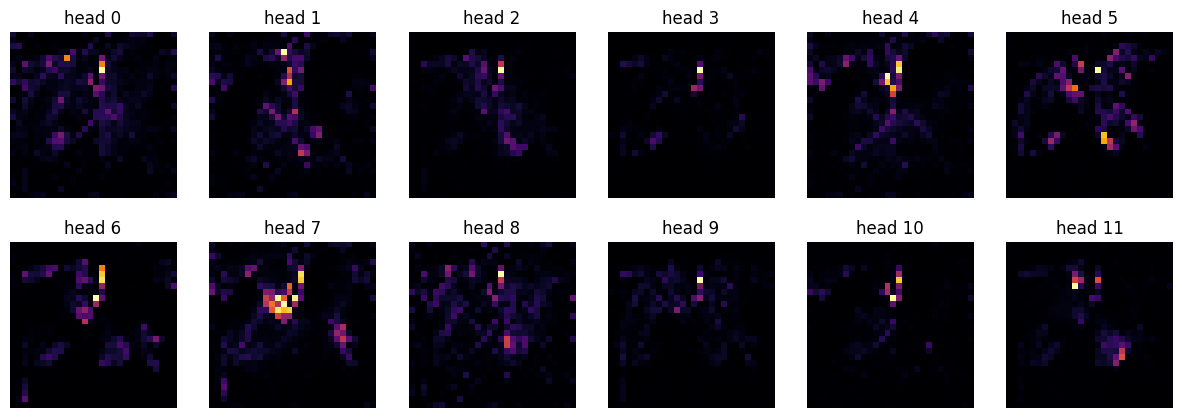

In [46]:
eager = AutoModel.from_pretrained(IDS["DINOv3-B"], torch_dtype=torch.float32,
                                  attn_implementation="eager").to(device).eval()

x = prep(img, 448).float()          # prep returns fp16, so cast it back
with torch.inference_mode():
    att = eager(pixel_values=x, output_attentions=True).attentions

R, g = eager.config.num_register_tokens, 448 // eager.config.patch_size
a = att[-1][0]                                        # (heads, T, T)
print("attention NaN:", torch.isnan(a).any().item())

cls_att = a[:, 0, 1 + R:].reshape(-1, g, g).cpu()
nh = cls_att.shape[0]
fig, ax = plt.subplots(2, nh // 2, figsize=(2.5 * nh // 2, 5))
for i, axi in enumerate(ax.flat):
    axi.imshow(cls_att[i], cmap="inferno"); axi.set_title(f"head {i}"); axi.axis("off")
plt.show()

##3. LayerScale values (a DINO-specific component)

In [47]:
vals = {}
for n, p in m.named_parameters():
    if "layer_scale" in n:
        vals[n] = p.detach().float().abs().mean().item()

for i in range(m.config.num_hidden_layers):
    s1 = [v for k, v in vals.items() if f"layer.{i}." in k and "scale1" in k]
    s2 = [v for k, v in vals.items() if f"layer.{i}." in k and "scale2" in k]
    print(f"block {i:2d}  attn gamma={s1[0]:.4f}  mlp gamma={s2[0]:.4f}")

block  0  attn gamma=0.0129  mlp gamma=0.1246
block  1  attn gamma=0.1734  mlp gamma=0.1660
block  2  attn gamma=0.1466  mlp gamma=0.2168
block  3  attn gamma=0.2031  mlp gamma=0.3878
block  4  attn gamma=0.4032  mlp gamma=0.5668
block  5  attn gamma=0.6954  mlp gamma=0.9554
block  6  attn gamma=1.1048  mlp gamma=1.6999
block  7  attn gamma=1.7062  mlp gamma=2.6258
block  8  attn gamma=2.2037  mlp gamma=5.1371
block  9  attn gamma=3.7150  mlp gamma=8.6897
block 10  attn gamma=6.2996  mlp gamma=11.7388
block 11  attn gamma=17.7606  mlp gamma=8.6256


##4. RoPE and aspect ratio

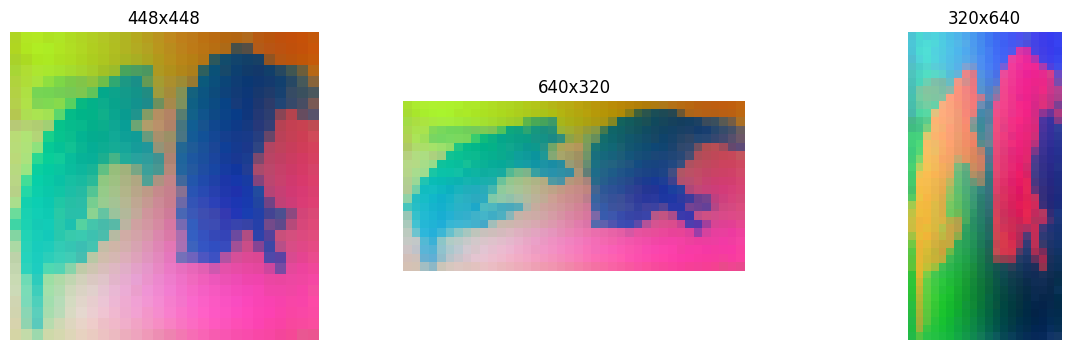

In [49]:
@torch.inference_mode()
def dense_hw(model, img, h, w):
    x = norm(T.ToTensor()(img.resize((w, h), Image.BICUBIC))).unsqueeze(0).to(device).half()
    out = model(pixel_values=x).last_hidden_state[0]
    R = model.config.num_register_tokens; p = model.config.patch_size
    return out[1 + R:].float().reshape(h // p, w // p, -1)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (h, w) in zip(ax, [(448, 448), (320, 640), (640, 320)]):
    a.imshow(pca_rgb(dense_hw(m, img, h, w))); a.set_title(f"{w}x{h}"); a.axis("off")
plt.show()

##5. Weight statistics (pure teardown, no images)

In [55]:
print([n for n, _ in m.named_children()])
print([n for n, _ in m.named_parameters() if "q_proj.weight" in n][:3])

qs = [(n, p) for n, p in m.named_parameters() if n.endswith("q_proj.weight")]
print(f"found {len(qs)} q_proj matrices")

for i in [0, len(qs) // 2, len(qs) - 1]:
    n, p = qs[i]
    W = p.detach().float()
    S = torch.linalg.svdvals(W)
    eff_rank = (S.sum() ** 2 / (S ** 2).sum()).item()   # participation ratio
    print(f"block {i:2d} q_proj: ||W||={W.norm():.1f}  effective rank={eff_rank:.0f}/{min(W.shape)}  ({n})")

['embeddings', 'rope_embeddings', 'model', 'norm']
['model.layer.0.attention.q_proj.weight', 'model.layer.1.attention.q_proj.weight', 'model.layer.2.attention.q_proj.weight']
found 12 q_proj matrices
block  0 q_proj: ||W||=83.1  effective rank=41/768  (model.layer.0.attention.q_proj.weight)
block  6 q_proj: ||W||=43.2  effective rank=432/768  (model.layer.6.attention.q_proj.weight)
block 11 q_proj: ||W||=32.5  effective rank=365/768  (model.layer.11.attention.q_proj.weight)


##6. Unsupervised object discovery (no training)

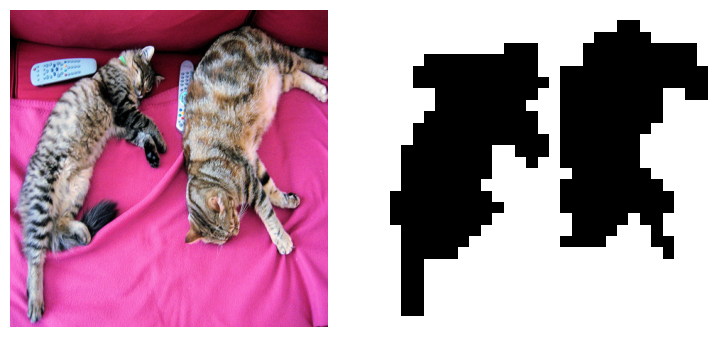

In [56]:
f = dense(m, img, 448)
x = f.reshape(-1, f.shape[-1]); x = x - x.mean(0)
_, _, V = torch.pca_lowrank(x, q=1)
pc1 = (x @ V[:, :1]).reshape(g, g).cpu()
mask = (pc1 > pc1.mean()) if pc1[g // 2, g // 2] > pc1.mean() else (pc1 < pc1.mean())  # keep the center-side as foreground
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
ax[0].imshow(img.resize((448, 448))); ax[1].imshow(mask, cmap="gray")
for a in ax: a.axis("off")
plt.show()